# 06 · Interpretación (Fases 8 y 9)
Dos miradas independientes: (1) un modelo explicativo ponderado con errores robustos por diseño muestral, y (2) importancia por permutación del modelo predictivo. Si coinciden, la evidencia converge.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.models import train as T
tr, te = T.split(df)
tabla, modelos = T.compare(tr, te, T.NUM, T.CAT)
elegido, mejor_auc = T.choose(tabla)
modelo = modelos[elegido]
from src.evaluation import interpret as I
from src.visualization import plots as V
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


,Razón de momios,IC 95% inf,IC 95% sup,p-valor
educ_madre = No sabe / ausente,0.746,0.442,1.257,0.271
educ_madre = Secundaria o más,0.724,0.417,1.258,0.252
educ_padre = No sabe / ausente,1.572,1.050,2.353,0.028
educ_padre = Secundaria o más,0.978,0.553,1.729,0.939
localidad_14 = Ciudad chica,0.478,0.176,1.300,0.148
localidad_14 = Ciudad grande,0.471,0.156,1.423,0.182
localidad_14 = Ciudad mediana,0.467,0.165,1.318,0.150
"localidad_14 = Pueblo (<2,500)",0.771,0.303,1.966,0.586
region_14 = Centro-norte,0.574,0.326,1.012,0.055
region_14 = Norte,0.398,0.192,0.825,0.013


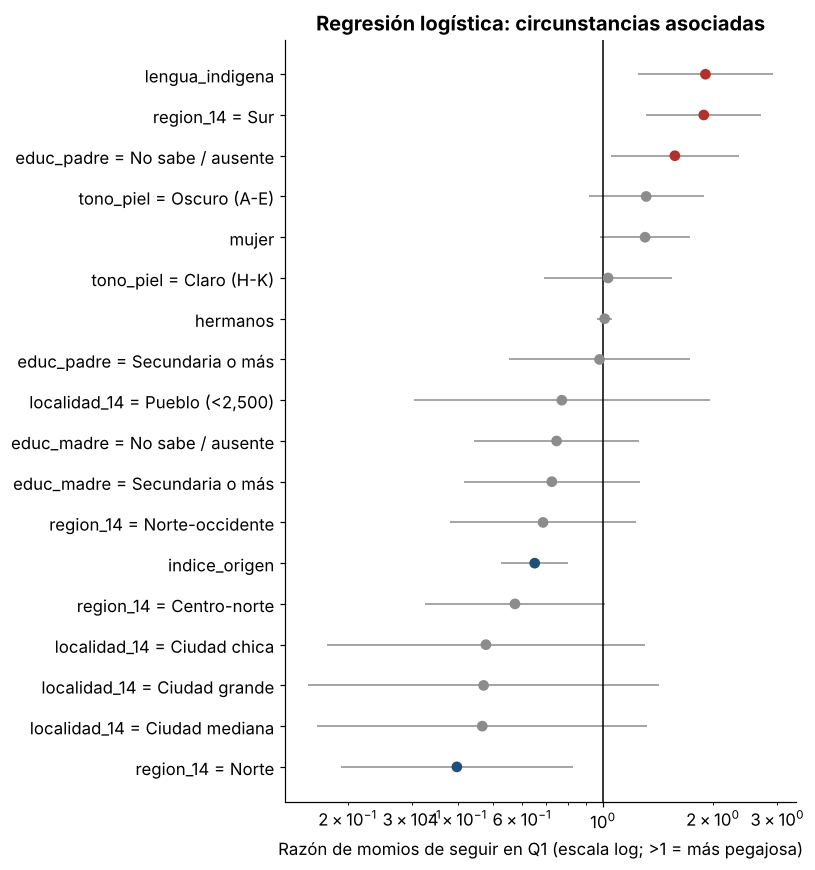

In [2]:
or_, m = I.logit_explicativo(q1)
or_.to_csv(TABLES / "razones_momios.csv"); display(or_); V.razones_momios(or_); plt.show()

**Cómo leer una razón de momios:** 1 = sin asociación; 1.9 = casi el doble de momios de seguir en Q1; 0.4 = 60% menos momios. Las comparaciones son contra: madre y padre con primaria o menos, metrópoli, región Centro, tono medio y cohorte 25-34.

,Variable,Pérdida de AUC,desv.
22,region_14,0.0712,0.0106
23,cohorte,0.0503,0.0122
0,indice_origen,0.0468,0.0078
25,autoadscripcion,0.0164,0.0052
18,educ_padre,0.0105,0.0045
6,lengua_indigena,0.0098,0.0051
21,localidad_14,0.0097,0.0044
14,o_p33e,0.0088,0.0015
4,personas_hogar_14,0.0082,0.0040
15,o_p33f,0.0080,0.0025


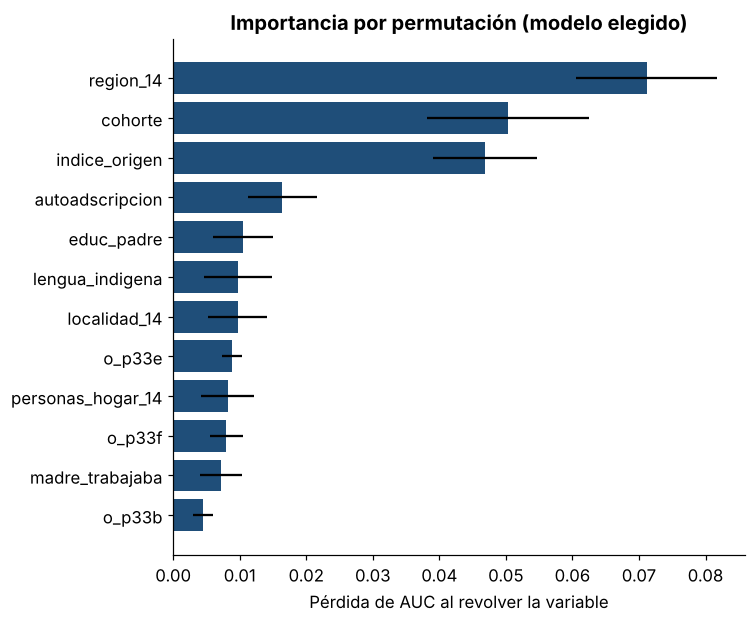

In [3]:
imp = I.importance(modelo, te, T.NUM, T.CAT)
imp.to_csv(TABLES / "importancia_permutacion.csv", index=False); display(imp.head(12)); V.importancia(imp); plt.show()

## Tabla de convergencia de evidencia
| Hallazgo | Descriptivo (03) | Logit explicativo | Importancia ML | ¿Converge? |
|---|---|---|---|---|
| Región Sur más pegajosa | ✅ | ✅ RM ≈ 1.9 | ✅ variable n.º 1 | **Sí** |
| Lengua indígena | ✅ | ✅ RM ≈ 1.9 | ✅ moderada | **Sí** |
| Más riqueza de origen dentro de Q1 ayuda | — | ✅ RM ≈ 0.65 | ✅ alta | **Sí** |
| Cohortes jóvenes más atrapadas | ✅ | ✅ | ✅ | Sí, pero puede ser un artefacto de medición (ver 08) |
| Tono de piel | ✅ en la descripción | ❌ no significativo al controlar región y lengua | baja | **Parcial** |
| Escolaridad de la madre | débil | ❌ no significativa dentro de Q1 | baja | **No**: casi no hay variación dentro de Q1 |